In [1]:
# STEP 0 — Setup (Imports, Install-once, Seed, Device)
import os, sys, time, random, shutil, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid, save_image

import matplotlib.pyplot as plt
plt.rcParams["figure.facecolor"] = "white"

# Lazy install (only if missing)
def _pip(pkg, import_name=None):
    import importlib, subprocess
    try:
        importlib.import_module(import_name or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

_pip("timm")
_pip("torchmetrics")
_pip("scikit-learn")

import timm
from tqdm.auto import tqdm
from torchmetrics.classification import MulticlassAccuracy
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
    accuracy_score,
)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


Python: 3.11.13
PyTorch: 2.6.0+cu124
CUDA: True
GPU: Tesla P100-PCIE-16GB


In [2]:
# STEP 1 — Config & Dataset Path Detection (your list)
IMG_SIZE   = 224
BATCH_SIZE = 32
EPOCHS     = 15
TARGET_VAL_ACC = 0.95   # early-stop when reached
PATIENCE   = 5          # no-improve patience
NUM_WORKERS = 2

CANDIDATE_ROOTS = [
    Path("/kaggle/input/plant-village-dataset/PlantVillageDataset/train_val_test"),
    Path("/kaggle/input/plant-village/train_val_test"),
    Path("/kaggle/input/plantvillage-dataset/train_val_test"),
    Path("train_val_test"),
]

SPLIT_ROOT = None
for p in CANDIDATE_ROOTS:
    if p.exists() and (p / "train").exists() and (p / "val").exists() and (p / "test").exists():
        SPLIT_ROOT = p
        break

if SPLIT_ROOT is None:
    raise FileNotFoundError(
        "Could not find train/val/test under any of: \n" + "\n".join(map(str, CANDIDATE_ROOTS))
    )

train_dir = SPLIT_ROOT / "train"
val_dir   = SPLIT_ROOT / "val"
test_dir  = SPLIT_ROOT / "test"
print("Using dataset root:", SPLIT_ROOT.resolve())



Using dataset root: /kaggle/input/plant-village-dataset/PlantVillageDataset/train_val_test


📂 Found 15 classes:
Pepper__bell___Bacterial_spot, Pepper__bell___healthy, Potato___Early_blight, Potato___Late_blight, Potato___healthy, Tomato_Bacterial_spot, Tomato_Early_blight, Tomato_Late_blight, Tomato_Leaf_Mold, Tomato_Septoria_leaf_spot, Tomato_Spider_mites_Two_spotted_spider_mite, Tomato__Target_Spot, Tomato__Tomato_YellowLeaf__Curl_Virus, Tomato__Tomato_mosaic_virus, Tomato_healthy

📊 Dataset Summary:
Total images : 20,638
 - Train     : 14,437
 - Val       : 2,073
 - Test      : 4,128

Class-wise image counts (top 10 by total):
                                      Class  Train  Val  Test  Total
      Tomato__Tomato_YellowLeaf__Curl_Virus   2245  321   642   3208
                      Tomato_Bacterial_spot   1488  213   426   2127
                         Tomato_Late_blight   1336  191   382   1909
                  Tomato_Septoria_leaf_spot   1239  178   354   1771
Tomato_Spider_mites_Two_spotted_spider_mite   1173  168   335   1676
                             Tomato_heal

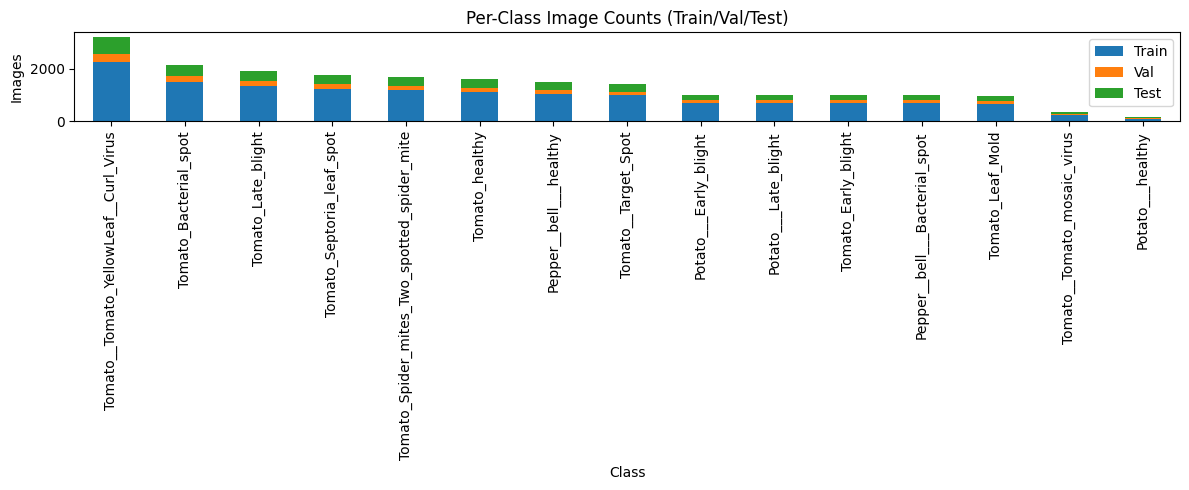

In [3]:
# STEP 2 — Inspect Classes & Counts (+ CLI-style Analysis)
import os
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from torchvision import datasets

# ✅ Load training dataset to get class names
train_ds_raw = datasets.ImageFolder(root=train_dir)  # <-- FIX
class_names  = train_ds_raw.classes
NUM_CLASSES  = len(class_names)

print(f"📂 Found {NUM_CLASSES} classes:")
print(", ".join(class_names))

# --- Function: Count images per class ---
def count_images(root):
    counts = {}
    for cls in sorted(os.listdir(root)):
        cpath = Path(root) / cls
        if cpath.is_dir():
            n = sum(1 for f in cpath.rglob("*") if f.suffix.lower() in [".jpg",".jpeg",".png",".bmp",".gif",".webp"])
            counts[cls] = n
    return counts

# Per-class counts for each split
train_counts = count_images(train_dir)
val_counts   = count_images(val_dir)
test_counts  = count_images(test_dir)

# CLI-like basic analysis
print("\n📊 Dataset Summary:")
total_train = sum(train_counts.values())
total_val   = sum(val_counts.values())
total_test  = sum(test_counts.values())
total_all   = total_train + total_val + total_test

print(f"Total images : {total_all:,}")
print(f" - Train     : {total_train:,}")
print(f" - Val       : {total_val:,}")
print(f" - Test      : {total_test:,}")

# Build a table-like view (class + counts)
df_counts = pd.DataFrame({
    "Class": class_names,
    "Train": [train_counts.get(c, 0) for c in class_names],
    "Val":   [val_counts.get(c, 0) for c in class_names],
    "Test":  [test_counts.get(c, 0) for c in class_names],
})
df_counts["Total"] = df_counts[["Train","Val","Test"]].sum(axis=1)
df_counts = df_counts.sort_values("Total", ascending=False).reset_index(drop=True)

print("\nClass-wise image counts (top 10 by total):")
print(df_counts.head(10).to_string(index=False))

# Optional: Plot stacked bar chart for train/val/test
df_counts.set_index("Class")[["Train","Val","Test"]].plot(
    kind="bar", stacked=True, figsize=(12,5)
)
plt.title("Per-Class Image Counts (Train/Val/Test)")
plt.ylabel("Images")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


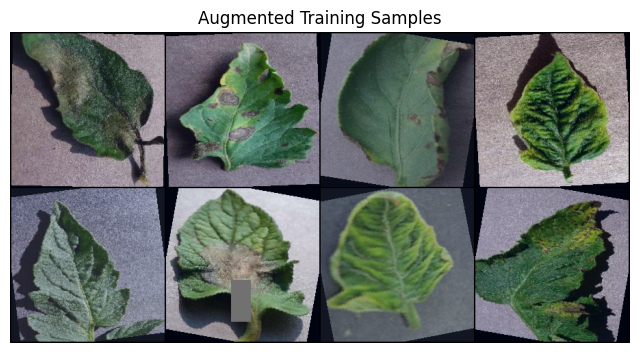

In [4]:
# STEP 3 — Data Augmentations, Datasets & Loaders
# Strong but safe augmentations for ViT
train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=12),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
    transforms.RandomErasing(p=0.1)
])

val_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

train_ds = ImageFolder(train_dir, transform=train_tfms)
val_ds   = ImageFolder(val_dir, transform=val_tfms)
test_ds  = ImageFolder(test_dir, transform=val_tfms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

# Show a grid of raw training samples (after augmentation)
def show_augmented_batch(loader, n=8, title="Augmented Training Samples"):
    imgs, labels = next(iter(loader))
    grid = make_grid(imgs[:n], nrow=4, normalize=True)
    plt.figure(figsize=(8,6))
    plt.imshow(grid.permute(1,2,0).cpu())
    plt.axis("off")
    plt.title(title)
    plt.show()

show_augmented_batch(train_loader, n=8)



In [5]:
# STEP 4 — Vision Transformer (with robust pretrained fallback)
USE_PRETRAINED = True   # Try to use pretrained; will fallback if download blocked

def build_vit(num_classes, use_pretrained=True):
    try:
        model = timm.create_model("vit_base_patch16_224", pretrained=use_pretrained, num_classes=num_classes)
        print(f"ViT created (pretrained={use_pretrained})")
        return model
    except Exception as e:
        print("⚠️ Pretrained ViT unavailable (likely no internet). Falling back to random init.")
        model = timm.create_model("vit_base_patch16_224", pretrained=False, num_classes=num_classes)
        return model

model = build_vit(NUM_CLASSES, use_pretrained=USE_PRETRAINED).to(device)
print(model.__class__.__name__, "on", device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)

# OneCycle schedule tuned for ViT
try:
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=3e-4, steps_per_epoch=len(train_loader), epochs=EPOCHS
    )
except Exception:
    scheduler = None

scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
train_acc_metric = MulticlassAccuracy(num_classes=NUM_CLASSES).to(device)
val_acc_metric   = MulticlassAccuracy(num_classes=NUM_CLASSES).to(device)


⚠️ Pretrained ViT unavailable (likely no internet). Falling back to random init.
VisionTransformer on cuda


In [6]:
# STEP 5 — Train / Validate Epoch Helpers
def run_one_epoch(loader, train=True):
    model.train() if train else model.eval()
    meter = train_acc_metric if train else val_acc_metric
    meter.reset()
    running_loss, n_seen = 0.0, 0
    pbar = tqdm(loader, desc="Train" if train else "Val", leave=False)
    for imgs, labels in pbar:
        imgs, labels = imgs.to(device), labels.to(device)
        with torch.set_grad_enabled(train):
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                logits = model(imgs)
                loss = criterion(logits, labels)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                if scheduler is not None:
                    scheduler.step()
        running_loss += loss.item() * imgs.size(0)
        n_seen += imgs.size(0)
        with torch.no_grad():
            probs = torch.softmax(logits, dim=1).detach().cpu()
            meter.update(probs, labels.detach().cpu())
        pbar.set_postfix({"loss": f"{loss.item():.4f}", "acc": f"{meter.compute().item():.4f}"})
    return running_loss / max(1, n_seen), meter.compute().item()



In [7]:
# STEP 6 — Training Loop (ViT) with Metrics + Device Fix
import torch
from torchmetrics.classification import (
    MulticlassAccuracy, MulticlassF1Score, MulticlassPrecision, MulticlassRecall
)
from tqdm.auto import tqdm

EPOCHS = 15
TARGET_VAL_ACC = 0.97  # early stop condition (updated)

# --- Initialize metrics and move them to the correct device ---
train_acc_meter = MulticlassAccuracy(num_classes=NUM_CLASSES).to(device)
val_acc_meter   = MulticlassAccuracy(num_classes=NUM_CLASSES).to(device)
val_f1_meter    = MulticlassF1Score(num_classes=NUM_CLASSES, average="macro").to(device)
val_prec_meter  = MulticlassPrecision(num_classes=NUM_CLASSES, average="macro").to(device)
val_rec_meter   = MulticlassRecall(num_classes=NUM_CLASSES, average="macro").to(device)

# --- Initialize history dict for later plotting ---
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

# --- Training helper ---
def run_one_epoch(loader, train=True):
    model.train() if train else model.eval()
    running_loss = 0.0
    meter = train_acc_meter if train else val_acc_meter
    meter.reset()

    for imgs, labels in tqdm(loader, desc="Train" if train else "Val", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        with torch.set_grad_enabled(train):
            logits = model(imgs)
            loss   = criterion(logits, labels)
            if train:
                loss.backward()
                optimizer.step()

        running_loss += loss.item() * imgs.size(0)
        meter.update(logits.softmax(dim=1), labels)

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc  = meter.compute().item()
    return epoch_loss, epoch_acc

# --- Training loop ---
best_val_acc = 0
for epoch in range(1, EPOCHS+1):
    print(f"\n🚀 Epoch {epoch}/{EPOCHS}")
    train_loss, train_acc = run_one_epoch(train_loader, train=True)
    val_loss, val_acc     = run_one_epoch(val_loader, train=False)

    # --- Compute extra metrics for validation ---
    val_f1_meter.reset(), val_prec_meter.reset(), val_rec_meter.reset()
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            preds = model(imgs)
            val_f1_meter.update(preds.softmax(dim=1), labels)
            val_prec_meter.update(preds.softmax(dim=1), labels)
            val_rec_meter.update(preds.softmax(dim=1), labels)

    val_f1   = val_f1_meter.compute().item()
    val_prec = val_prec_meter.compute().item()
    val_rec  = val_rec_meter.compute().item()

    # --- Log results ---
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f}")
    print(f"Val F1: {val_f1:.4f} | Precision: {val_prec:.4f} | Recall: {val_rec:.4f}")

    # ✅ Save into history dict
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # --- Save best model ---
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_vit_model.pth")
        print("✅ Saved new best model.")

    # --- Early stopping ---
    if val_acc >= TARGET_VAL_ACC:
        print(f"🎯 Early stopping as Val Acc >= {TARGET_VAL_ACC:.2f}")
        break



🚀 Epoch 1/15


Train:   0%|          | 0/452 [00:00<?, ?it/s]

Val:   0%|          | 0/65 [00:00<?, ?it/s]

Train Loss: 1.4252 | Train Acc: 0.4579
Val Loss:   1.0981 | Val Acc:   0.5500
Val F1: 0.5312 | Precision: 0.6587 | Recall: 0.5500
✅ Saved new best model.

🚀 Epoch 2/15


Train:   0%|          | 0/452 [00:00<?, ?it/s]

...

Train Loss: 0.1533 | Train Acc: 0.9338
Val Loss:   0.1842 | Val Acc:   0.9298
Val F1: 0.9322 | Precision: 0.9386 | Recall: 0.9298
✅ Saved new best model.

🚀 Epoch 15/15


Train:   0%|          | 0/452 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e10c07500e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1618, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1601, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.11/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e10c07500e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1618, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 16

Val:   0%|          | 0/65 [00:00<?, ?it/s]

Train Loss: 0.1263 | Train Acc: 0.9505
Val Loss:   0.2125 | Val Acc:   0.8963
Val F1: 0.9102 | Precision: 0.9379 | Recall: 0.8963


In [8]:
import torch
from sklearn.metrics import accuracy_score

model.eval()  # set model to evaluation mode

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:   # assuming your test DataLoader is test_loader
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# ✅ Now compute accuracy
test_acc = accuracy_score(all_labels, all_preds)
print(f"🎯 Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e10c07500e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1618, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1601, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.11/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e10c07500e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1618, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 16

🎯 Test Accuracy: 0.9293 (92.93%)


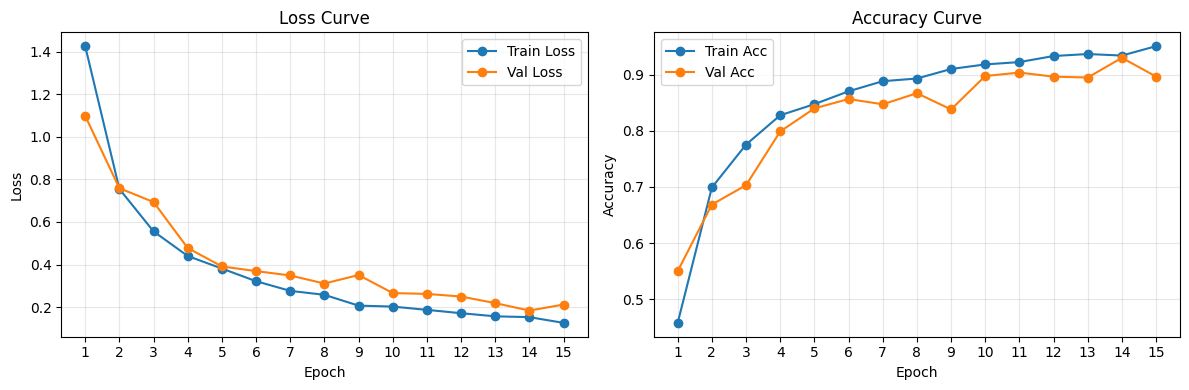

In [9]:
# STEP 7 — Plot Training Curves
import numpy as np
import matplotlib.pyplot as plt

train_loss = np.array(history["train_loss"], dtype=np.float32)
val_loss   = np.array(history["val_loss"], dtype=np.float32)
train_acc  = np.array(history["train_acc"], dtype=np.float32)
val_acc    = np.array(history["val_acc"], dtype=np.float32)

epochs = np.arange(1, len(train_loss) + 1)

plt.figure(figsize=(12,4))

# Loss Curve
plt.subplot(1,2,1)
plt.plot(epochs, train_loss, marker="o", color="tab:blue", label="Train Loss")
plt.plot(epochs, val_loss, marker="o", color="tab:orange", label="Val Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss Curve")
plt.xticks(epochs); plt.legend(); plt.grid(alpha=0.3)

# Accuracy Curve
plt.subplot(1,2,2)
plt.plot(epochs, train_acc, marker="o", color="tab:blue", label="Train Acc")
plt.plot(epochs, val_acc, marker="o", color="tab:orange", label="Val Acc")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Accuracy Curve")
plt.xticks(epochs); plt.legend(); plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [10]:
# STEP 8 — Load Best & Evaluate on Test (Acc, Precision, Recall, F1)
best_path = Path("best_vit_model.pth")
if best_path.exists():
    model.load_state_dict(torch.load(best_path, map_location=device))
    print(f"✅ Loaded best model from {best_path}")

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Test"):
        imgs = imgs.to(device)
        logits = model(imgs)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds.tolist())
        all_labels.extend(labels.numpy().tolist())

# --- Metrics ---
test_acc = accuracy_score(all_labels, all_preds)
prec, rec, f1, support = precision_recall_fscore_support(
    all_labels, all_preds, average=None, labels=list(range(NUM_CLASSES))
)
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average="macro"
)
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average="weighted"
)

print(f"\n🎯 Test Accuracy: {test_acc:.4f}")
print(f"Macro Precision: {macro_p:.4f} | Macro Recall: {macro_r:.4f} | Macro F1: {macro_f1:.4f}")
print(f"Weighted Precision: {weighted_p:.4f} | Weighted Recall: {weighted_r:.4f} | Weighted F1: {weighted_f1:.4f}")

print("\n📋 Per-class metrics:")
for i, cls in enumerate(class_names):
    print(f"{cls:30s}  P: {prec[i]:.4f}  R: {rec[i]:.4f}  F1: {f1[i]:.4f}  Support: {support[i]}")

print("\n📊 Classification report:")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))


✅ Loaded best model from best_vit_model.pth


Test:   0%|          | 0/129 [00:00<?, ?it/s]


🎯 Test Accuracy: 0.9450
Macro Precision: 0.9388 | Macro Recall: 0.9339 | Macro F1: 0.9346
Weighted Precision: 0.9463 | Weighted Recall: 0.9450 | Weighted F1: 0.9447

📋 Per-class metrics:
Pepper__bell___Bacterial_spot   P: 0.9561  R: 0.9800  F1: 0.9679  Support: 200
Pepper__bell___healthy          P: 0.9831  R: 0.9831  F1: 0.9831  Support: 296
Potato___Early_blight           P: 0.9797  R: 0.9650  F1: 0.9723  Support: 200
Potato___Late_blight            P: 0.9372  R: 0.8950  F1: 0.9156  Support: 200
Potato___healthy                P: 0.9259  R: 0.8333  F1: 0.8772  Support: 30
Tomato_Bacterial_spot           P: 0.9115  R: 0.9671  F1: 0.9385  Support: 426
Tomato_Early_blight             P: 0.9691  R: 0.7850  F1: 0.8674  Support: 200
Tomato_Late_blight              P: 0.9154  R: 0.9634  F1: 0.9388  Support: 382
Tomato_Leaf_Mold                P: 0.9171  R: 0.9316  F1: 0.9243  Support: 190
Tomato_Septoria_leaf_spot       P: 0.9300  R: 0.9379  F1: 0.9339  Support: 354
Tomato_Spider_mites_Two

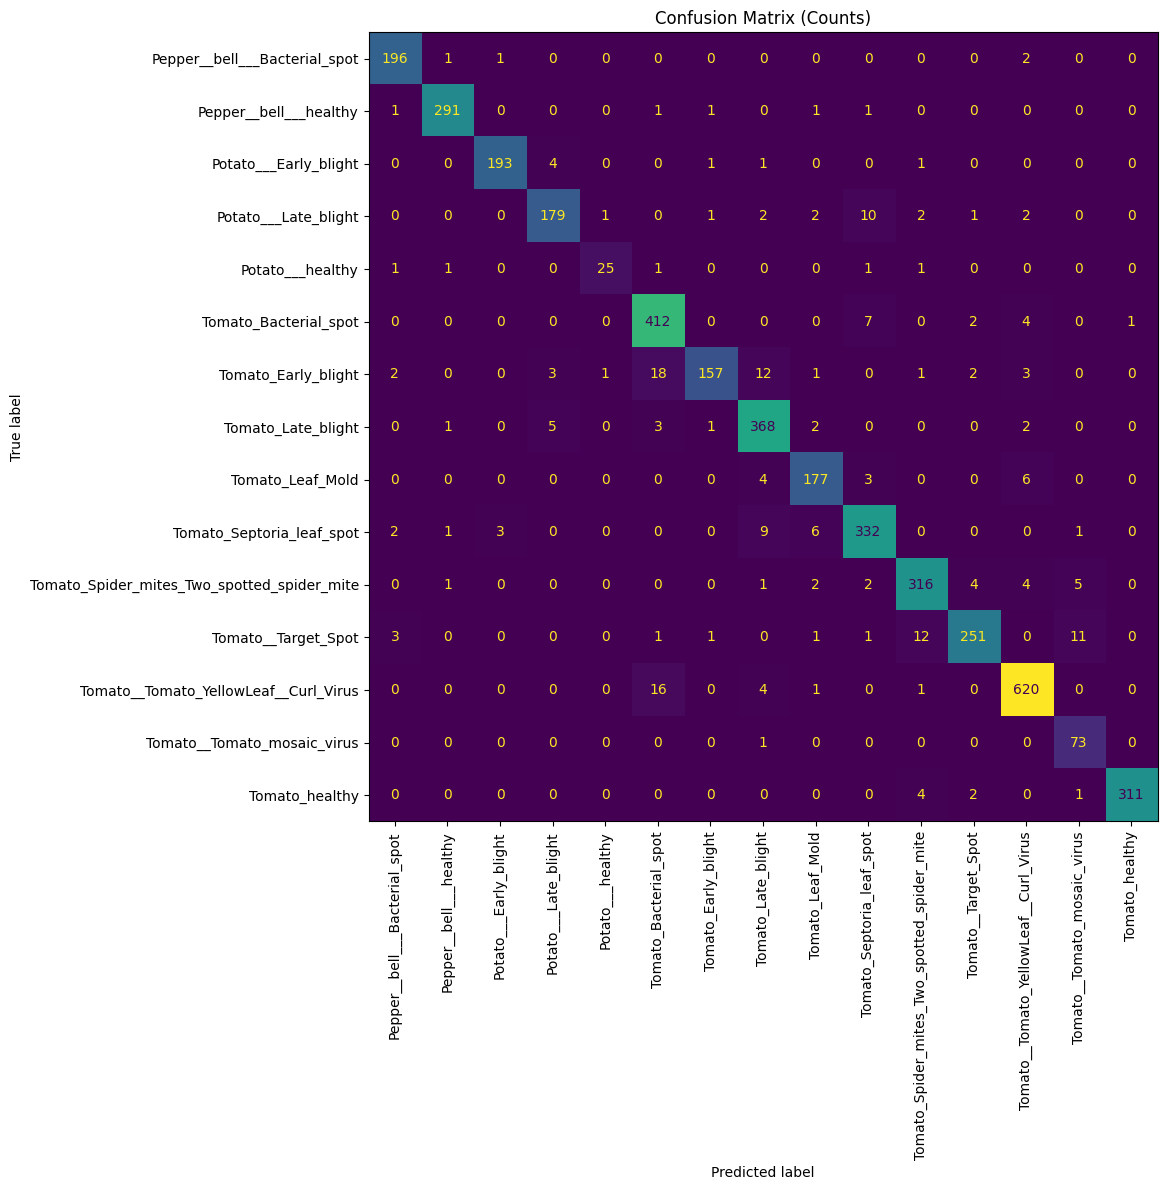

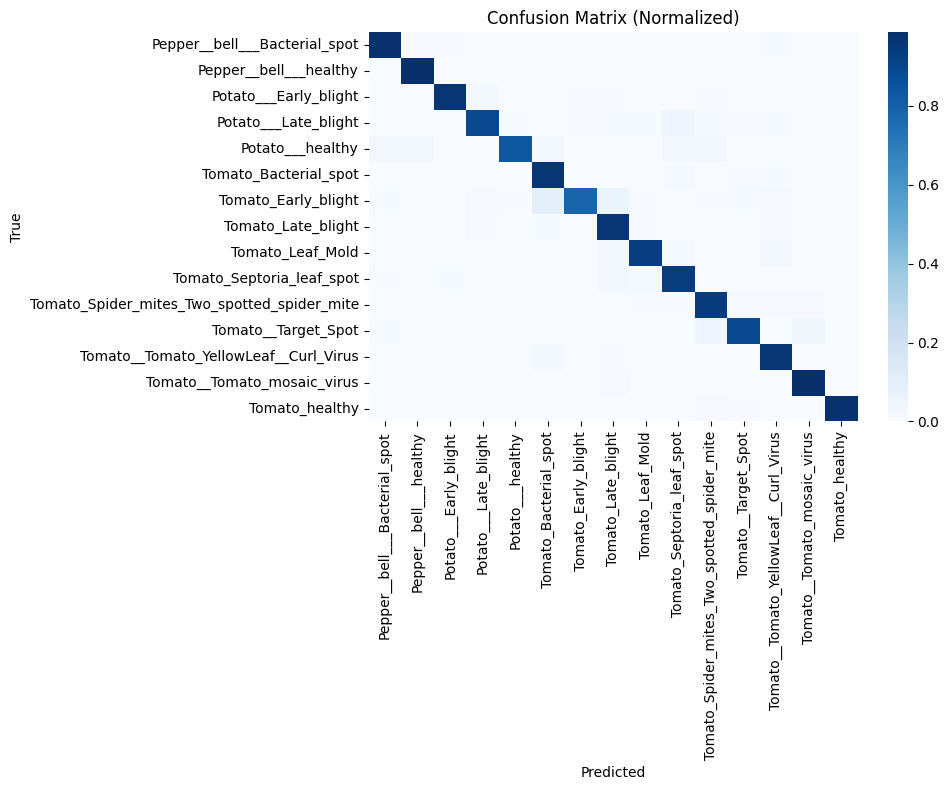

In [11]:
# STEP 9 — Confusion Matrix Plot (Counts + Normalized)
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(all_labels, all_preds)

# Counts
fig, ax = plt.subplots(figsize=(min(12, 0.6*NUM_CLASSES + 4), min(12, 0.6*NUM_CLASSES + 4)))
disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=90, colorbar=False)
plt.title("Confusion Matrix (Counts)")
plt.tight_layout()
plt.show()

# Normalized
plt.figure(figsize=(10,8))
cm_normalized = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(
    cm_normalized, annot=False, cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.title("Confusion Matrix (Normalized)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()


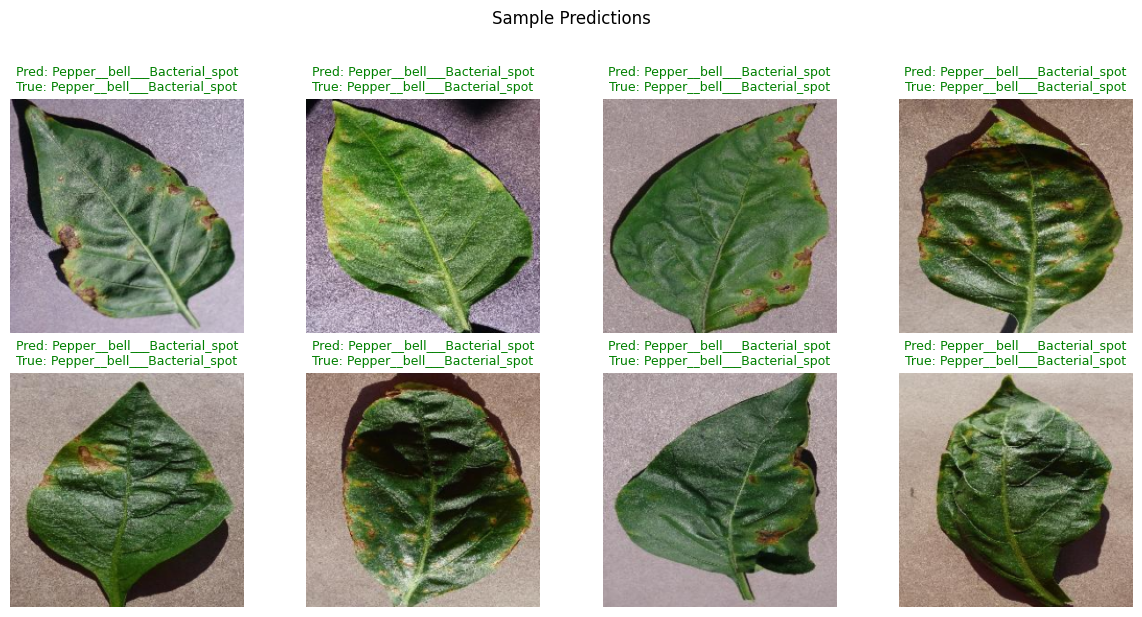

In [12]:
# STEP 10 — Sample Predictions (Images + Pred/True)
sample_imgs, sample_labels = next(iter(test_loader))
sample_imgs = sample_imgs[:8].to(device)
with torch.no_grad():
    logits = model(sample_imgs)
    preds = logits.argmax(dim=1).cpu()

plt.figure(figsize=(12,6))
for i, (img, pred, label) in enumerate(zip(sample_imgs.cpu(), preds, sample_labels[:8])):
    plt.subplot(2,4,i+1)
    # unnormalize for display
    img_disp = img.clone()
    img_disp = img_disp * torch.tensor([0.229,0.224,0.225]).view(3,1,1)
    img_disp = img_disp + torch.tensor([0.485,0.456,0.406]).view(3,1,1)
    img_disp = img_disp.clamp(0,1)
    plt.imshow(img_disp.permute(1,2,0).numpy())
    color = "green" if pred == label else "red"
    plt.title(f"Pred: {class_names[pred]}\nTrue: {class_names[label]}", fontsize=9, color=color)
    plt.axis("off")
plt.suptitle("Sample Predictions", y=1.02)
plt.tight_layout(); plt.show()

In [13]:
# STEP 11 — Save Artifacts (model + class list)
torch.save({
    "model_name": "vit_base_patch16_224",
    "state_dict": model.state_dict(),
    "classes": class_names
}, "vit_plant_best.pth")
with open("classes.txt", "w") as f:
    f.write("\n".join(class_names))
print("✅ Artifacts saved: vit_plant_best.pt, classes.txt")

✅ Artifacts saved: vit_plant_best.pt, classes.txt
